# 11 - Probabilidade mensal de água Dynamic World (10 m)

| | |
|---|---|
| **Tarefa do plano** | Reforço da Camada 2 (P2) |
| **Variáveis (Parte I)** | #43 cobertura do solo quase em tempo real, classe `water` |
| **Fonte** | Dynamic World V1 (Google/WRI) via Earth Engine `GOOGLE/DYNAMICWORLD/V1` |
| **Saída** | `data/raw/land_cover/dynamic_world/<ano>/` |

Bandas: probabilidade média mensal de `water` e `flooded_vegetation`, a classe
mais frequente (`label_mode`, 0-8) e `n_obs`. O Dynamic World é produzido a partir
do Sentinel-2 por um modelo, por isso é uma **feature**, não um rótulo
independente para o Modelo B.

Correr primeiro `00_setup_and_authentication` e `01_study_area_aoi`. Todos os
downloads podem ser retomados: os ficheiros que já existem são saltados, e cada
ficheiro fica registado em `data/metadata/download_manifest.csv`.

In [2]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import ee
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, datasets, gee, series
from ete import grid as G

cfg = config.load_config()
gee.init(cfg)

aoi = G.load_aoi(cfg)                       # AOI das imagens (EPSG:4326)
region = gee.ee_geometry(aoi)
grid30 = G.load_grid(cfg)                   # grelha do projeto a 30 m (EPSG:32736)
grid10 = G.load_grid(cfg, 10)               # grelha a 10 m, encaixada na de 30 m
climate_bounds = tuple(G.load_aoi(cfg, "aoi_climate").total_bounds)   # O, S, E, N
MASK = gee.ee_geometry(G.imagery_mask(cfg))  # distrito + margem: fora daqui as imagens mensais ficam sem dados

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## Parâmetros

**Formato dos ficheiros.** Os valores são guardados como inteiros (`DTYPE`), multiplicados
por `SCALE`, para ocupar menos disco e menos internet sem perda relevante de precisão.
O fator fica gravado dentro do GeoTIFF: ler sempre com `series.read_scaled(ficheiro)`,
que devolve os valores físicos. As bandas `n_obs` e `label_mode` não são multiplicadas.
Com `MASK`, os píxeis fora do distrito + margem ficam sem dados (-9999).

In [3]:
ds = cfg["datasets"]["dynamic_world"]
DATASET, SOURCE_ID = "dynamicworld", ds["id"]
BANDS = ["water", "flooded_vegetation", "label_mode", "n_obs"]
GRID, DTYPE, START = grid10, "int16", ds["start"]
SCALE = 10000                               # probabilidades guardadas como inteiro (x10000)
OUT_DIR = config.path(cfg, "dynamic_world")
builder = datasets.dynamic_world_builder(cfg, region)

## Teste com um mês

Correr sempre um mês primeiro e observá-lo antes de lançar o período completo.
`2023-02` está na época chuvosa, quando as nuvens e as cheias são mais prováveis.

In [3]:
TEST_MONTH = "2023-02"
test = gee.download_monthly(cfg, DATASET, SOURCE_ID, builder, BANDS, GRID, OUT_DIR,
                            start=f"{TEST_MONTH}-01", end=f"{TEST_MONTH}-28", dtype=DTYPE, scale=SCALE, mask=MASK)
test

dynamicworld:   0%|          | 0/1 [00:00<?, ?it/s]

,period,status,file,n_images
0,2023-02,downloaded,dynamicworld_marracuene_2023-02_10m.tif,11


<Axes: title={'center': 'dynamicworld_marracuene_2023-02_10m.tif\nn_obs'}>

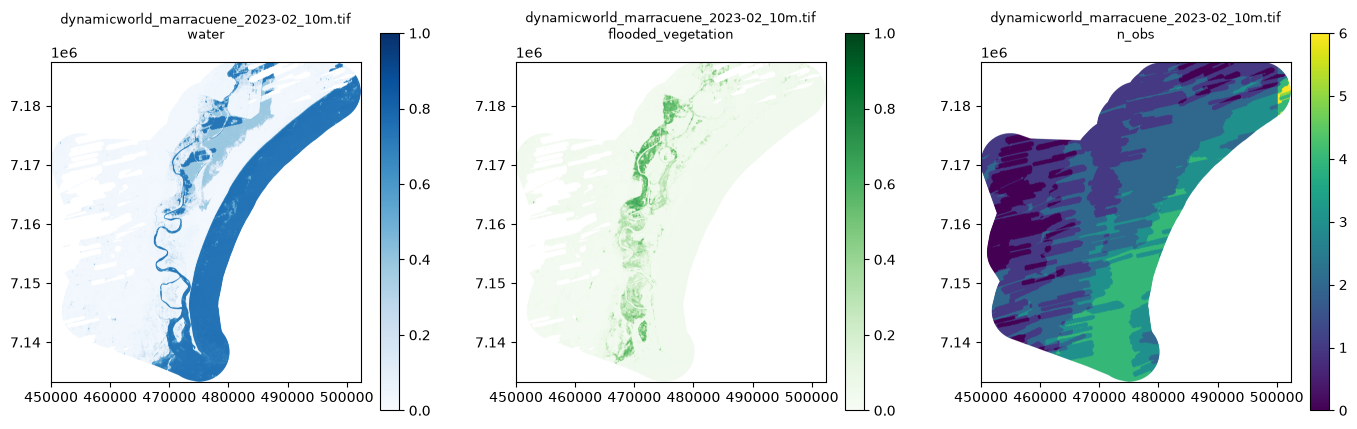

In [4]:
test_file = next(OUT_DIR.rglob(f"*_{TEST_MONTH}_*.tif"))
fig, axes = plt.subplots(1, 3, figsize=(17, 7))
series.show_raster(test_file, band="water", ax=axes[0], cmap="Blues", vmin=0, vmax=1)
series.show_raster(test_file, band="flooded_vegetation", ax=axes[1], cmap="Greens", vmin=0, vmax=1)
series.show_raster(test_file, band="n_obs", ax=axes[2], cmap="viridis")

## Período completo

Demora bastante (horas para os datasets de 10 m). Pode ser interrompido e
retomado a qualquer momento; os meses já concluídos são saltados.

In [4]:
log = gee.download_monthly(cfg, DATASET, SOURCE_ID, builder, BANDS, GRID, OUT_DIR, start=START, dtype=DTYPE, scale=SCALE, mask=MASK)
log["status"].value_counts()

dynamicworld:   0%|          | 0/135 [00:00<?, ?it/s]

status
exists        81
downloaded    52
absent         2
Name: count, dtype: int64

## Inventário

In [ ]:
inv = series.monthly_inventory(OUT_DIR)
expected = [m.strftime("%Y-%m") for m in gee.month_starts(START, config.period_end(cfg))]
missing = sorted(set(expected) - set(inv["period"]))
print(f"{len(inv)} ficheiros, {inv['size_mb'].sum() / 1e3:.2f} GB em disco")
print(f"{len(missing)} de {len(expected)} meses sem ficheiro (ausentes na fonte ou com falha):")
print(missing)

133 ficheiros, 4.84 GB em disco
2 de 135 meses sem ficheiro (ausentes na fonte ou com falha):
['2015-07', '2015-08']


: 